![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 1. Waveguides

Welcome to our Photonic Integrated Circuits Laboratory! Throughout the course, we will be using a Python package called [GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html). This is an open-source tool, and is a great alternative to other commercial software like Synopsys Optodesigner, Luceda Photonics, or Lumerical/Interconnect. Since it runs on Python, you have two options for executing your laboratory tasks:

1. **Local installation on your own PC** (Recommended): Please note that we will not spend class time on installing the software. However, feel free to reach out if you need help with the installation.

2. **Cloud Workspace**: Alternatively, you can use a cloud-based solution if the Local installation does not work.

## 0. Imports

For this laboratory you will need the following libraries:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td

import gplugins as gp
import gplugins.tidy3d as gt
from gplugins import plot
from gplugins.common.config import PATH

nm = 1e-3
wavelength = np.linspace(1500, 1600,11) * nm
f = td.C_0 / wavelength


In [2]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

## LO.1. Effective index of a waveguide

### Convergence Tests
We have asumed until now, that the **real** value of the effective index for each cross-section is the value provided by this mode-solver. However, this number relies on a numerical method, making it sensible to some input parameters, such as the selected grid. The objective of this section is to find the dependence of the **calculated** value of the effective index with the *grid_resolution* and the *max_grid_scaling*, the two parameters that we can modify from the automatic grid function used at the gt.modes.Waveguide() function.  <br>
- Consider a 1.2 um width deep waveguide (SiNx), with 0.3 um height operating at 1550 nm.
    - Sweep the *grid_resolution* between 10 and 100 in steps of 10. Plot the **calculated** effective index vs the *grid_resolution*. 
    - Select a value for the *grid_resolution* from the latter sweep (where the calculated index remains almost constant), and sweep the *max_grid_scaling* from 1.2 to 1.6 in steps of 0.1. Plot the **calculated** effective index vs the *max_grid_scaling*.
    - Conclude which will be the best configuration for the grid parameters for this particular case. 

  0%|          | 0/10 [00:00<?, ?it/s]

2026-11-08 23:34:49.542 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_09770a5eb4303d37.npz.
2026-11-08 23:34:49.550 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_972b4c36731994ce.npz.
2026-11-08 23:34:49.553 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4aa1037aeb7bae0f.npz.
2026-11-08 23:34:49.555 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4a7cfe924ea84b0e.npz.
2026-11-08 23:34:49.557 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a75f11ee34197d65.npz.
2026-11-08 23:34:49.559 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9f3aaac580067da9.npz.
2026-11-08 23:34:49.560 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a122f2de27436370.npz.
2026-11-08 23:34:49.562 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_55052adad499f4e5.npz.


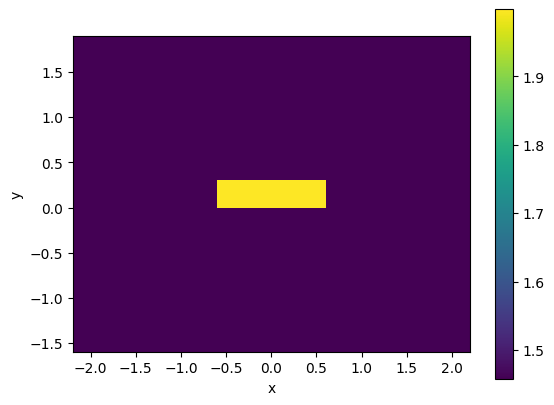

In [3]:
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

deep_waveguide.plot_index()

# Student continue your code here ...
grid_resolution_sweep= np.linspace(10, 100, 10)
sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, grid_resolution=grid_resolution_sweep)

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


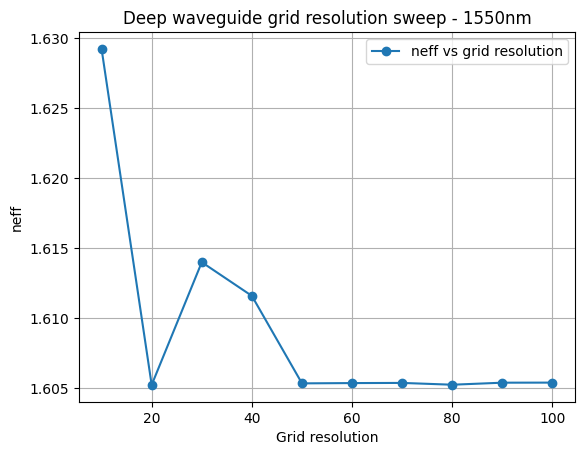

In [4]:

plt.plot(grid_resolution_sweep, sweep_neff, label="neff vs grid resolution", marker='o')
plt.title("Deep waveguide grid resolution sweep - 1550nm")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
plt.legend()

<div style="background-color: #2d3545; border-left: 5px solid #e0a33a; padding: 12px; border-radius: 5px;">

### 💬 Comentarios
La parte donde el indice efectivo se estabiliza es en el rango de 60 a 100 de Grid Resolution, tomamos por tanto el 100 como parámetro y calculamos ahora el sweep en max grid scaling, ya que con el mayor valor psoible de the grid resolution mejor resultado obtendremos

  0%|          | 0/5 [00:00<?, ?it/s]

2026-11-08 23:34:49.837 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_6885164a4e710b87.npz.
2026-11-08 23:34:49.840 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_30dc74c6e4246497.npz.
2026-11-08 23:34:49.842 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d0e57cc2f9463bc0.npz.
2026-11-08 23:34:49.843 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_734506418d905a04.npz.
2026-11-08 23:34:49.846 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_8510b6ff68ce0946.npz.


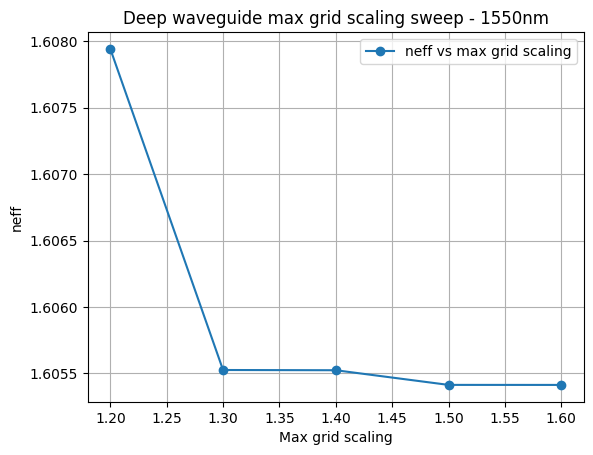

In [5]:
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=100, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)
max_grid_scaling_sweep= np.linspace(1.2, 1.6, 5)
sweep_neff_max_grid_scaling = gt.modes.sweep_n_eff(deep_waveguide, max_grid_scaling=max_grid_scaling_sweep)
plt.plot(max_grid_scaling_sweep, sweep_neff_max_grid_scaling, label="neff vs max grid scaling", marker='o')
plt.title("Deep waveguide max grid scaling sweep - 1550nm")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
plt.legend()

<div style="background-color: #2d3545; border-left: 5px solid #e0a33a; padding: 12px; border-radius: 5px;">

### 💬 Comentarios
Max_grid_scaling: Parámetro que trata de maximizar la malla computacional, cuanto mayor es la malla mayor coste computacional 

1.30: buena relación entre precisión y coste computacional.



1.50: opción más conservadora si quieres asegurar la convergencia del resultado.



1.60: no parece aportar una mejora apreciable respecto a 1.50.

## LO.2. Width dependence

- Perform a sweep of the **deep** waveguide width. Use the code provided in the following cell or program your own sweep. 

  0%|          | 0/10 [00:00<?, ?it/s]

2026-11-08 23:34:49.986 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e0f2a62752cad497.npz.
2026-11-08 23:34:49.988 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3ae06f0e9b897b42.npz.
2026-11-08 23:34:49.991 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_423ace54e9018435.npz.
2026-11-08 23:34:49.993 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_13798a9e51464563.npz.
2026-11-08 23:34:49.995 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_31a376b5383f892d.npz.
2026-11-08 23:34:49.998 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5586c4316050ebc7.npz.
2026-11-08 23:34:50.001 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2373487c3ad0b4df.npz.
2026-11-08 23:34:50.004 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7305bddb54556681.npz.


  0%|          | 0/10 [00:00<?, ?it/s]

2026-11-08 23:34:50.016 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e0f2a62752cad497.npz.
2026-11-08 23:34:50.019 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_3ae06f0e9b897b42.npz.
2026-11-08 23:34:50.021 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_423ace54e9018435.npz.
2026-11-08 23:34:50.023 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_13798a9e51464563.npz.
2026-11-08 23:34:50.025 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_31a376b5383f892d.npz.
2026-11-08 23:34:50.027 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5586c4316050ebc7.npz.
2026-11-08 23:34:50.029 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2373487c3ad0b4df.npz.
2026-11-08 23:34:50.030 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_7305bddb54556681.npz.


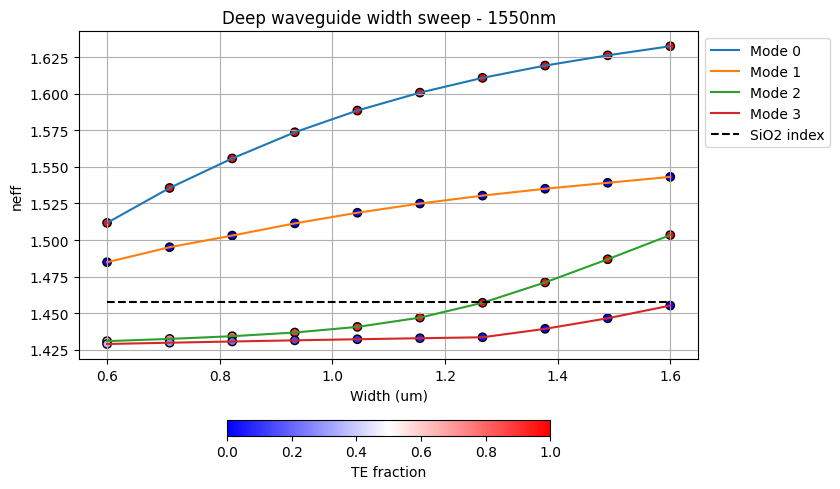

In [6]:
wavelength = 1550 * nm  # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)

w = np.linspace(600,1600, 10) * nm  # Student code here

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (um)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

## LO.3. Waveguide compact model

A compact model of an integrated photonic waveguide is a reduced-order mathematical model that describes the waveguide’s optical behavior—such as phase propagation, loss, and dispersion, using analytical or semi-analytical equations. Consider: 

Transfer function for propagation in a waveguide:

$$
H(\lambda)
= e^{-j\,\beta(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\beta(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\beta(\lambda)\}\,z}.
$$

Where 

$$
\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\}.
$$

Let's model the waveguide's effective index wavelength variation using a second order polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Where 

1. 
$$
n_\mathrm{eff}(\lambda_0) = n_1
$$
2. 
$$
n_g(\lambda_0) = n_1 - n_2\,\lambda_0
$$
3. 
$$
D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

- Find the **compact models** of the following waveguides: 
    - Deep waveguide, height = 300nm, width = 1.2um 
    - Shallow waveguide, core height = 300nm, slab height = 150 nm, width = 1.2um 

**TIP**. Use the Lab0.1.Modesolver results (neff vs lambda) as starting point. Fit the results using a second order polynomial (with the lambda_0 shift) and relate the fit results to n_g and D values.

<div style="background-color: #2d3545; border-left: 5px solid #e0a33a; padding: 12px; border-radius: 5px;">

### 💬 Comentarios
When we have a devide with one input (in0) & one output (out0). Los parametros a tener en cuenta son la wavelength, propagation constant $$\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\} $$ que tiene que ver con el neff, y está relacionada a parte con la geometría, lo polarizacion TE/TM, y cuando hablamos de 3D es la longitud (length).
Definimos el group index como: $$ n_g(\lambda_0) = n_1 - n_2\,\lambda_0 $$
Si tenemos una gran diferencia entre refractive index y effective index, cuando más alto sea el slope, más alto será el group index.
Si tenemos un alto parametro de dispersión, quiere decir que el comportamiento estará lejos de ser un comportamiento lineal y el parámetro de dispersión será alto.
Tenemos que "shiftear" around los puntos para hallar correctamente el fit y luego podemos comprobar con el neff(lambda0)=n1 si hemos hecho correctamente el desplazamiento

## Deep Waveguide



In [7]:
wavelength = np.linspace(1.5, 1.6, 11)

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=1.2, 
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)
# Calculate TE and TM fractions for each wavelength

res_te = []
res_tm = []

for wl in wavelength:

    wg = gt.modes.Waveguide(
        wavelength=wl,
        core_width=1.2,
        slab_thickness=0.0,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=4,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20,
    )

    res_te.append(wg.fraction_te)
    res_tm.append(wg.fraction_tm)

res_te = np.array(res_te) #Convert into an array the waveguide TE fraction results
res_tm = np.array(res_tm) # The same with the TM fraction results

print("TE shape:", res_te.shape)
print("TM shape:", res_tm.shape)

res_neff = deep_waveguide.n_eff.real

# Waveguide at 1550 nm
deep_waveguide_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm, 
    core_width=1.2, 
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)

res_neff_1550 = deep_waveguide_1550.n_eff.real

print(f"neff at 1550nm: {res_neff_1550}")

# Identify TE and TM modes at 1550 nm
posicion_lambda = np.argmin(np.abs(wavelength - 1.55))

te_1550 = res_te[posicion_lambda, :]
tm_1550 = res_tm[posicion_lambda, :]

i_TE = np.where(te_1550 > 0.5)[0][0]
i_TM = np.where(tm_1550 > 0.5)[0][0]

print(f"TE: Mode {i_TE}, fraction = {te_1550[i_TE]:.3f}")
print(f"TM: Mode {i_TM}, fraction = {tm_1550[i_TM]:.3f}")

2026-11-08 23:34:50.256 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d8b40731f944ee4c.npz.
2026-11-08 23:34:50.259 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_137ab38d8a0a42ec.npz.
2026-11-08 23:34:50.262 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_af46027037e963cc.npz.
2026-11-08 23:34:50.264 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ddeec7a6ef33317a.npz.
2026-11-08 23:34:50.265 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_af80b72133698e3a.npz.
2026-11-08 23:34:50.268 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_29761b037c0c9026.npz.
2026-11-08 23:34:50.270 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c596429ac7215d2c.npz.
2026-11-08 23:34:50.272 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4d01f080a8259d2d.npz.


Wavelength: [1.5  1.51 1.52 1.53 1.54 1.55 1.56 1.57 1.58 1.59 1.6 ]
neff: [1.61596895 1.61371946 1.61148949 1.60927904 1.60708809 1.60491662
 1.60276464 1.60063211 1.59851902 1.59642535 1.59435107]


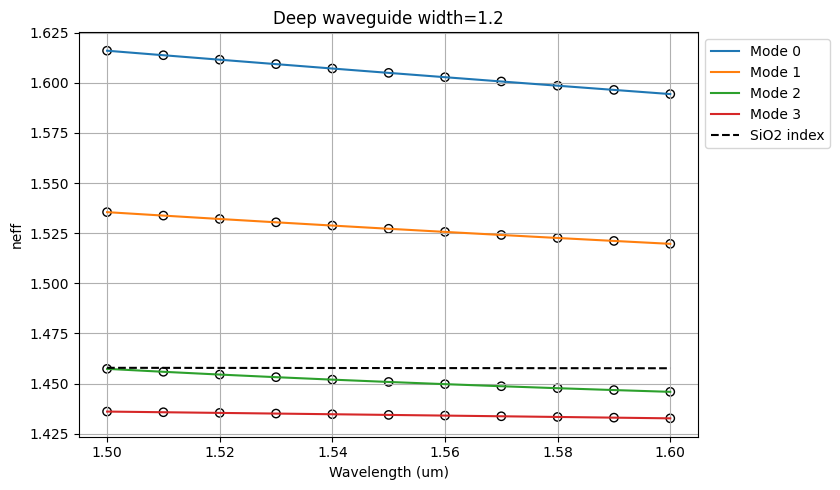

In [8]:
plt.figure(figsize=(10, 5)) #Getting the figure ready to plot
for k in range(res_neff.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
print(f"Wavelength: {wavelength}")
print(f"neff: {res_neff[:,0].real}")

In [9]:
# Mode 0 TE0
n3p,n2p,n1p = np.polyfit(wavelength-1.55, res_neff[:,0], 2)

# Mode 1 TM0
n3p_1,n2p_1,n1p_1 = np.polyfit(wavelength-1.55, res_neff[:,1], 2)

print(f"Mode 0: n3 = {n3p}, n2 = {n2p}, n1 = {n1p}")
print(f"Mode 1: n3 = {n3p_1}, n2 = {n2p_1}, n1 = {n1p_1}")

# Group index
ng_0 = n1p-n2p*1.55
ng_1 = n1p_1-n2p_1*1.55

print(f"Group index Mode 0: {ng_0}")
print(f"Group index Mode 1: {ng_1}")

# Dispersion
D_0 = -2*1.55e-6/3e8*n3p
D_1 = -2*1.55e-6/3e8*n3p_1

print(f"Dispersion Mode 0: {D_0}")
print(f"Dispersion Mode 1: {D_1}")

Mode 0: n3 = 0.09735506571548527, n2 = -0.21617694948863667, n1 = 1.6049166291026742
Mode 1: n3 = 0.1538317132379166, n2 = -0.1579587829277265, n1 = 1.5271892343288158
Group index Mode 0: 1.939990900810061
Group index Mode 1: 1.772025347866792
Dispersion Mode 0: -1.006002345726681e-15
Dispersion Mode 1: -1.5895943701251383e-15


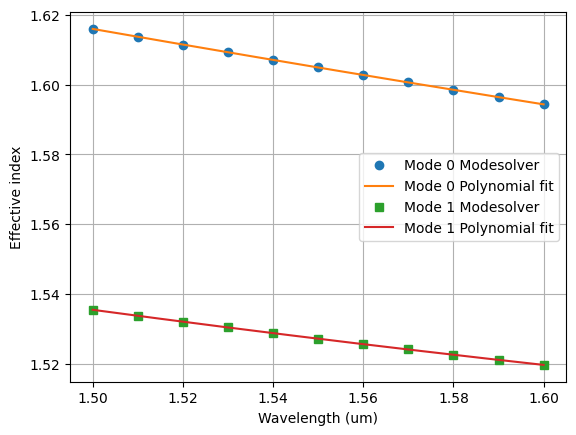

In [10]:
wavelength_fit = np.linspace(wavelength.min(), wavelength.max(), 200)
x_fit = wavelength_fit - 1.55

neff_fit_0 = np.polyval([n3p, n2p, n1p], x_fit)
neff_fit_1 = np.polyval([n3p_1, n2p_1, n1p_1], x_fit)

plt.plot(wavelength, res_neff[:,0], 'o', label="Mode 0 Modesolver")
plt.plot(wavelength_fit, neff_fit_0, label="Mode 0 Polynomial fit")

plt.plot(wavelength, res_neff[:,1], 's', label="Mode 1 Modesolver")
plt.plot(wavelength_fit, neff_fit_1, label="Mode 1 Polynomial fit")

plt.xlabel("Wavelength (um)")
plt.ylabel("Effective index")
plt.legend()
plt.grid()
plt.show()

## The Shallow Waveguide

In [11]:
wavelength=np.linspace(1.5, 1.6, 11)
shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=1.2, 
    slab_thickness=150 * nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)
res_neff_shallow = shallow_waveguide.n_eff.real

# Calculate TE and TM fractions for each wavelength

res_te = []
res_tm = []

for wl in wavelength:

    shallow_waveguide = gt.modes.Waveguide(
        wavelength=wl,
        core_width=1.2,
        slab_thickness=150 * nm,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=4,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20,
    )

    res_te.append(shallow_waveguide.fraction_te)
    res_tm.append(shallow_waveguide.fraction_tm)

res_te = np.array(res_te)
res_tm = np.array(res_tm)

print("TE shape:", res_te.shape)
print("TM shape:", res_tm.shape)


# Waveguide at 1550 nm
shallow_waveguide_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm, 
    core_width=1.2, 
    slab_thickness=150 * nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)

res_neff_1550 = shallow_waveguide_1550.n_eff.real

print(f"neff at 1550nm: {res_neff_1550}")

# Identify TE and TM modes at 1550 nm
posicion_lambda = np.argmin(np.abs(wavelength - 1.55))
print(res_te[posicion_lambda,0])
te_1550 = res_te[posicion_lambda, :]
tm_1550 = res_tm[posicion_lambda, :]

i_TE = np.where(te_1550 > 0.5)[0][0]
i_TM = np.where(tm_1550 > 0.5)[0][0]

print(f"TE: Mode {i_TE}, fraction = {te_1550[i_TE]:.3f}")
print(f"TM: Mode {i_TM}, fraction = {tm_1550[i_TM]:.3f}")

2026-11-08 23:34:50.584 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cf0af488213d9e23.npz.
2026-11-08 23:34:50.587 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_ed8642fa40d3627a.npz.
2026-11-08 23:34:50.589 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_1d0d4ea058a293f6.npz.
2026-11-08 23:34:50.591 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_22f62f6d87ac4e89.npz.
2026-11-08 23:34:50.594 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d5474e2efc925d1b.npz.
2026-11-08 23:34:50.597 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_09a13302606e71c7.npz.
2026-11-08 23:34:50.602 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_285238a48af05435.npz.
2026-11-08 23:34:50.606 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d73fb6280e8b2098.npz.


Wavelength: [1.5  1.51 1.52 1.53 1.54 1.55 1.56 1.57 1.58 1.59 1.6 ]
neff: [1.63373911 1.63177064 1.62982164 1.62789202 1.62598171 1.62409063
 1.62221868 1.6203658  1.61853188 1.61671685 1.61492062]


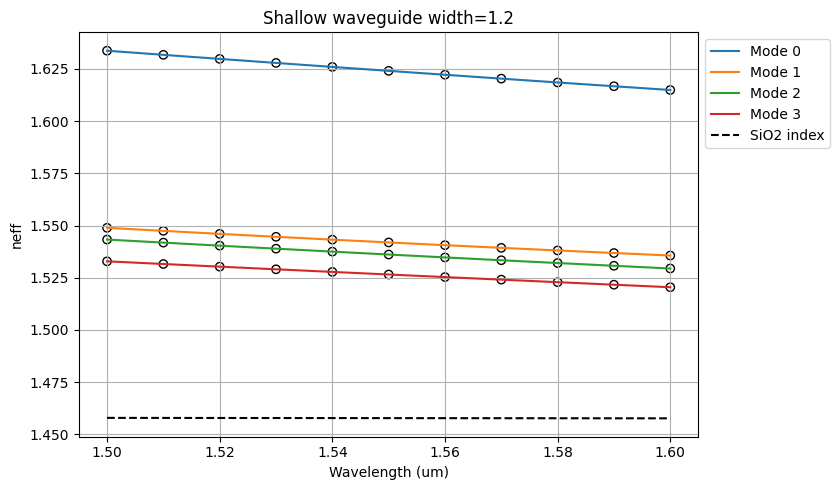

In [12]:
plt.figure(figsize=(10, 5)) #Getting the figure ready to plot
for k in range(res_neff_shallow.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff_shallow[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff_shallow[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
print(f"Wavelength: {wavelength}")
print(f"neff: {res_neff_shallow[:,0].real}")

In [13]:
#Mode 0 TE0
n3ps,n2ps,n1ps = np.polyfit(wavelength-1.55, res_neff_shallow[:,0], 2)

# Mode 2 TM0
n3p_2,n2p_2,n1p_2 = np.polyfit(wavelength-1.55, res_neff_shallow[:,2], 2)

print(f"Mode 0: n3 = {n3ps}, n2 = {n2ps}, n1 = {n1ps}")
print(f"Mode 2: n3 = {n3p_2}, n2 = {n2p_2}, n1 = {n1p_2}")

# Group index
ng_0 = n1ps-n2ps*1.55
ng_2 = n1p_2-n2p_2*1.55

print(f"Group index Mode 0: {ng_0}")
print(f"Group index Mode 2: {ng_2}")

# Dispersion
D_0 = -2*1.55e-6/3e8*n3ps
D_2 = -2*1.55e-6/3e8*n3p_2

print(f"Dispersion Mode 0: {D_0}")
print(f"Dispersion Mode 2: {D_2}")

Mode 0: n3 = 0.09569580270901852, n2 = -0.18817489158079223, n1 = 1.6240906297465494
Mode 2: n3 = 0.097979411485667, n2 = -0.13866250321256818, n1 = 1.5361017569769997
Group index Mode 0: 1.9157617116967773
Group index Mode 2: 1.7510286369564803
Dispersion Mode 0: -9.888566279931914e-16
Dispersion Mode 2: -1.0124539186852256e-15


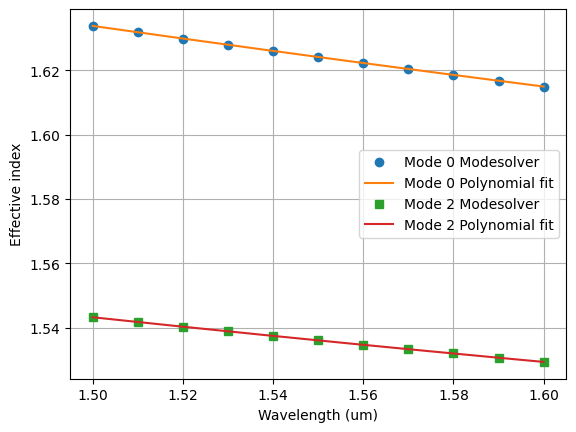

In [14]:
wavelength_fit = np.linspace(wavelength.min(), wavelength.max(), 200)
x_fit = wavelength_fit - 1.55

neff_fit_0 = np.polyval([n3ps, n2ps, n1ps], x_fit)
neff_fit_2 = np.polyval([n3p_2, n2p_2, n1p_2], x_fit)

plt.plot(wavelength, res_neff_shallow[:,0], 'o', label="Mode 0 Modesolver")
plt.plot(wavelength_fit, neff_fit_0, label="Mode 0 Polynomial fit")

plt.plot(wavelength, res_neff_shallow[:,2], 's', label="Mode 2 Modesolver")
plt.plot(wavelength_fit, neff_fit_2, label="Mode 2 Polynomial fit")

plt.xlabel("Wavelength (um)")
plt.ylabel("Effective index")
plt.legend()
plt.grid()
plt.show()

## LO.4. Bend waveguide radius vs. loss – deep

The bend loss has three primary contributions:

1. Mode-mismatch loss
2. Radiation loss
3. Propagation loss

In [43]:
bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1,
    slab_thickness=0.0,
    core_material='sin',    
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=30, 
    bend_radius=20, # Bend radius
)


In [44]:
res_te = []
res_tm = []

for wl in wavelength:

    BendWG = gt.modes.Waveguide(
        wavelength=wl,
        core_width=1,
        slab_thickness=150 * nm,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=4,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20,
    )

    res_te.append(BendWG.fraction_te)
    res_tm.append(BendWG.fraction_tm)

res_te = np.array(res_te)
res_tm = np.array(res_tm)

print("TE shape:", res_te.shape)
print("TM shape:", res_tm.shape)
#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------#
posicion_lambda = np.argmin(np.abs(wavelength - 1.55))
print(res_te[posicion_lambda,0])
te_1550 = res_te[posicion_lambda, :]
tm_1550 = res_tm[posicion_lambda, :]

i_TE = np.where(te_1550 > 0.5)[0][0]
i_TM = np.where(tm_1550 > 0.5)[0][0]

print(f"TE: Mode {i_TE}, fraction = {te_1550[i_TE]:.3f}")
print(f"TM: Mode {i_TM}, fraction = {tm_1550[i_TM]:.3f}")

2026-11-08 23:53:34.783 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_b5e6b650976a2ca6.npz.
2026-11-08 23:53:34.785 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_080cf22af2a9d721.npz.
2026-11-08 23:53:34.788 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d1e84fdb5faa9c87.npz.
2026-11-08 23:53:34.791 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f18d3b64a56a34e2.npz.
2026-11-08 23:53:34.793 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4e4da90d76bdc9ec.npz.
2026-11-08 23:53:34.796 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_dcce3a8eb790920e.npz.
2026-11-08 23:53:34.798 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cc23fd9859fa9915.npz.
2026-11-08 23:53:34.800 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5df65683dc48cf73.npz.


### Mode-mismatch loss

Bend waveguide mode differs slightly from the straight waveguide mode, wich yield into mode-convertion losses. We can calculate this factor with as the overlap of the latter two modes. 

This is already implemented on GDSfactory library: 

  0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\

23:55:21 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 1 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\

23:55:30 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

... (15 outputs left out)

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\

23:56:46 Hora estándar romance WARNING: Mode field at frequency index 0, mode   
                               index 2 does not decay at the plane boundaries.  

                               WARNING: Mode field at frequency index 0, mode   
                               index 3 does not decay at the plane boundaries.  

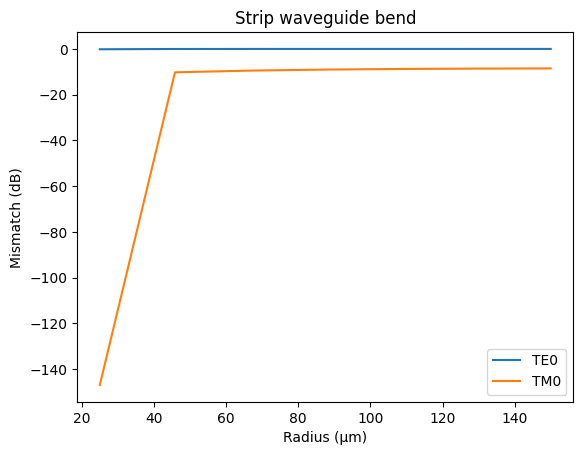

In [46]:
bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1000 * nm,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
    bend_radius=5, # Bend radius
)
radii = np.linspace(25, 150,7)

mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)

plt.plot(radii, 10 * np.log10(mismatch[:,0]), label='TE0')
plt.plot(radii, 10 * np.log10(mismatch[:,2]), label='TM0')
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.legend()

### Propagation loss

Consider the equivalent linear length of the quarter-circle bend. Light will attenuate following a trend quantified with the experimentally measured parameter $$\alpha [\mathrm{dB}/\mathrm{cm}]$$. It depends on the fabrication process mainly. We will add this loss (in dBs) to the mode-mismatch loss to calculate the total loss per bend. 

*We are not considering the radiation losses, mainly because is not easy to implement a quick simulation for this parameter. Under certain conditions, the main loss sources are the ones considered in this example


  0%|          | 0/7 [00:00<?, ?it/s]

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\

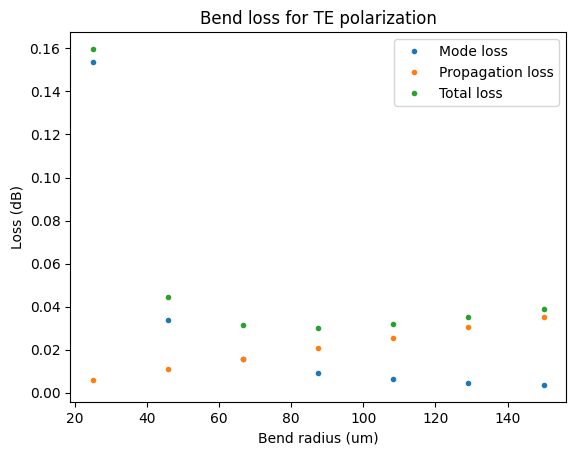

In [18]:
bend_1550_1mode = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1000 * nm,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=1,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.5,
    grid_resolution=60, 
    bend_radius=5, # Bend radius
)
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss = dB_cm * length * 1e2
propagation_loss
mismatch_1 = gt.modes.sweep_bend_mismatch(bend_1550_1mode, radii)
plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch_1), ".", label="Mode loss")
plt.plot(radii, propagation_loss, ".", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_1), ".", label="Total loss")
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()

## EXTRA

All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be 220 nm heigth and 500 nm width. 
1. Repeat the LO.1. wavelength behavior simulations, considering the updated materials and dimensions. 
2. Repeat the LO.3. width dependence analysis, now sweeping in a 300nm - 1um range. 
3. Find the safe radius for this technology. Consider sweeping the radius in a 5um to 30um range. 
4. **Compare the SiNx and SOI technologies** 

  0%|          | 0/10 [00:00<?, ?it/s]

2026-11-08 23:37:36.339 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_4a1d722b79a898fe.npz.
2026-11-08 23:37:36.342 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_03f4f47742c6dd39.npz.
2026-11-08 23:37:36.345 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_df6b8c7ded5c819f.npz.
2026-11-08 23:37:36.346 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e180c41701f0a45c.npz.
2026-11-08 23:37:36.348 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_99c2a1f132c5aa29.npz.
2026-11-08 23:37:36.350 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_376ad1e6757d68e9.npz.
2026-11-08 23:37:36.352 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d39692b947d95237.npz.
2026-11-08 23:37:36.354 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_778e926092e76bcf.npz.


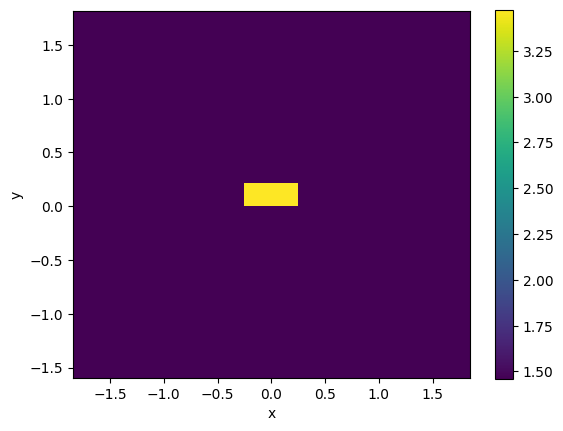

In [19]:
deep_waveguide_Si = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=500 *nm, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

deep_waveguide_Si.plot_index()

# Student continue your code here ...
grid_resolution_sweep= np.linspace(10, 100, 10)
sweep_neff = gt.modes.sweep_n_eff(deep_waveguide_Si, grid_resolution=grid_resolution_sweep)

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


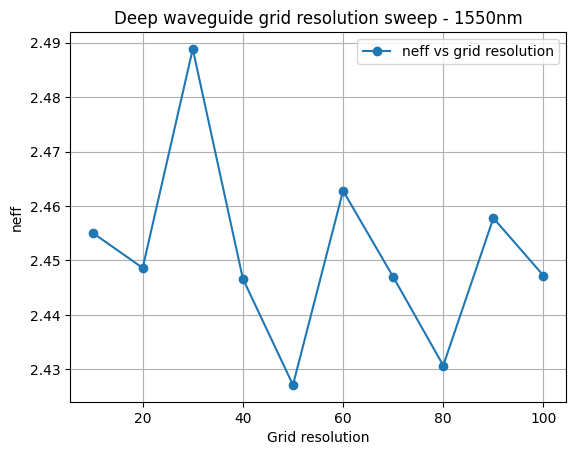

In [20]:
plt.plot(grid_resolution_sweep, sweep_neff, label="neff vs grid resolution", marker='o')
plt.title("Deep waveguide grid resolution sweep - 1550nm")
plt.xlabel("Grid resolution")
plt.ylabel("neff")
plt.grid()
plt.legend()

  0%|          | 0/5 [00:00<?, ?it/s]

2026-11-08 23:37:36.604 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cc4fc10128af5cd3.npz.
2026-11-08 23:37:36.606 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_0dde524baa930045.npz.
2026-11-08 23:37:36.608 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f1e069993e9b7864.npz.
2026-11-08 23:37:36.610 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_03f4f47742c6dd39.npz.
2026-11-08 23:37:36.612 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_e6ce3eac15aa54b7.npz.


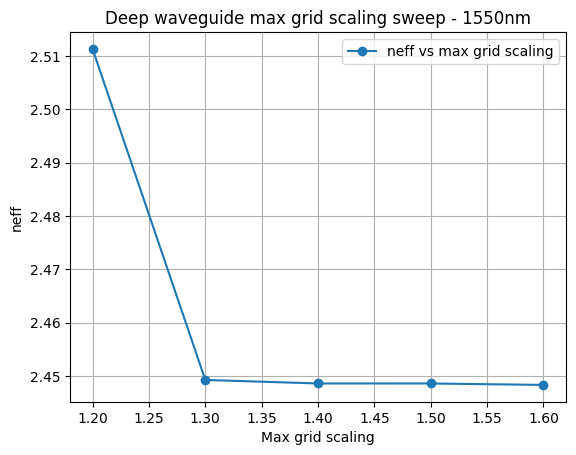

In [21]:
deep_waveguide_Si = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=500 *nm, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=1, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)
max_grid_scaling_sweep= np.linspace(1.2, 1.6, 5)
sweep_neff_max_grid_scaling = gt.modes.sweep_n_eff(deep_waveguide_Si, max_grid_scaling=max_grid_scaling_sweep)
plt.plot(max_grid_scaling_sweep, sweep_neff_max_grid_scaling, label="neff vs max grid scaling", marker='o')
plt.title("Deep waveguide max grid scaling sweep - 1550nm")
plt.xlabel("Max grid scaling")
plt.ylabel("neff")
plt.grid()
plt.legend()

## LO3- Deep WaveGuide
Repeat the LO.3. width dependence analysis, now sweeping in a 300nm - 1um range. 
All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be 220 nm heigth and 500 nm width. 

In [34]:
wavelength = np.linspace(1.5, 1.6, 11)

Deep_waveguide_Si = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=500 *nm, 
    slab_thickness=0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
) 

# Calculate TE and TM fractions for each wavelength

res_te = []
res_tm = []

for wl in wavelength:

    wg = gt.modes.Waveguide(
        wavelength=wl,
        core_width=500*nm,
        slab_thickness=0,
        core_material='si',
        clad_material='sio2',
        core_thickness=220 * nm,
        num_modes=4,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.4,
        grid_resolution=20,
    )

    res_te.append(wg.fraction_te)
    res_tm.append(wg.fraction_tm)

res_te = np.array(res_te) #Convert into an array the waveguide TE fraction results
res_tm = np.array(res_tm) # The same with the TM fraction results

print("TE shape:", res_te.shape)
print("TM shape:", res_tm.shape)

res_neff_si = Deep_waveguide_Si.n_eff.real

# Waveguide at 1550 nm
Deep_waveguide_si_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm, 
    core_width=500 *nm, 
    slab_thickness=0*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20,
)

res_neff_1550 = Deep_waveguide_si_1550.n_eff.real

print(f"neff at 1550nm: {res_neff_1550}")

# Identify TE and TM modes at 1550 nm
posicion_lambda = np.argmin(np.abs(wavelength - 1.55))

te_1550 = res_te[posicion_lambda, :]
tm_1550 = res_tm[posicion_lambda, :]

i_TE = np.where(te_1550 > 0.5)[0][0]
i_TM = np.where(tm_1550 > 0.5)[0][0]

print(f"TE: Mode {i_TE}, fraction = {te_1550[i_TE]:.3f}")
print(f"TM: Mode {i_TM}, fraction = {tm_1550[i_TM]:.3f}")

2026-11-08 23:46:08.689 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_174139ebe29358af.npz.
2026-11-08 23:46:08.693 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_f9ef4ac343b4087f.npz.
2026-11-08 23:46:08.696 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_79b82e18c5ecf5da.npz.
2026-11-08 23:46:08.698 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_2f6eb54e9e8176e6.npz.
2026-11-08 23:46:08.700 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_6a67b86dcd63c808.npz.
2026-11-08 23:46:08.703 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d2a12d2520042e19.npz.
2026-11-08 23:46:08.704 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_c43899c5b0c0dd78.npz.
2026-11-08 23:46:08.706 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_a2727d9b15540a60.npz.


Wavelength: [1.5  1.51 1.52 1.53 1.54 1.55 1.56 1.57 1.58 1.59 1.6 ]
neff: [2.45365823 2.44227263 2.43088465 2.41949465 2.40810305 2.39671029
 2.38531691 2.37392348 2.36253063 2.35113905 2.33974951]


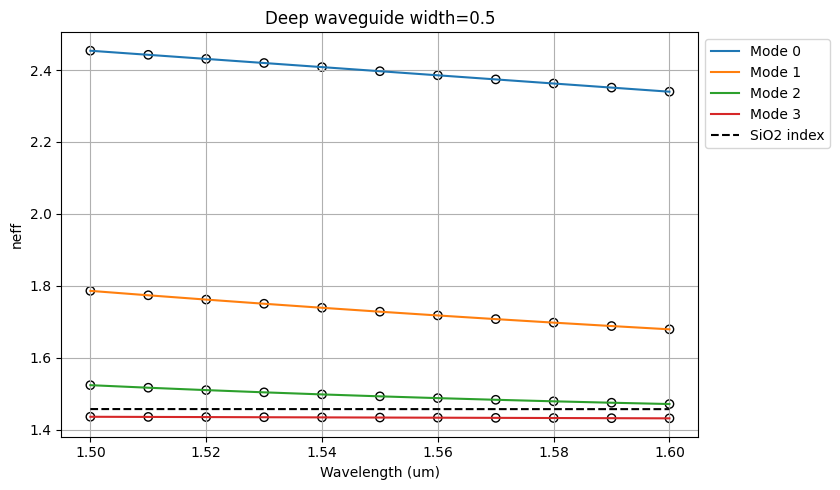

In [35]:
plt.figure(figsize=(10, 5)) #Getting the figure ready to plot
for k in range(res_neff_si.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff_si[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff_si[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={500*nm}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
print(f"Wavelength: {wavelength}")
print(f"neff: {res_neff_si[:,0].real}")

In [36]:
# Mode 0 TE0
n3p,n2p,n1p = np.polyfit(wavelength-1.55, res_neff_si[:,0], 2)

# Mode 1 TM0
n3p_1,n2p_1,n1p_1 = np.polyfit(wavelength-1.55, res_neff_si[:,1], 2)

print(f"Mode 0: n3 = {n3p}, n2 = {n2p}, n1 = {n1p}")
print(f"Mode 1: n3 = {n3p_1}, n2 = {n2p_1}, n1 = {n1p_1}")

# Group index
ng_0 = n1p-n2p*1.55
ng_1 = n1p_1-n2p_1*1.55

print(f"Group index Mode 0: {ng_0}")
print(f"Group index Mode 1: {ng_1}")

# Dispersion
D_0 = -2*1.55e-6/3e8*n3p
D_1 = -2*1.55e-6/3e8*n3p_1

print(f"Dispersion Mode 0: {D_0}")
print(f"Dispersion Mode 1: {D_1}")

Mode 0: n3 = -0.002569213266037536, n2 = -1.1391531400510868, n1 = 2.3967101216509605
Mode 1: n3 = 1.7668839578746147, n2 = -1.0680601801629783, n1 = 1.7284553770214495
Group index Mode 0: 4.162397488730145
Group index Mode 1: 3.383948656274066
Dispersion Mode 0: 2.654853708238787e-17
Dispersion Mode 1: -1.8257800898037684e-14


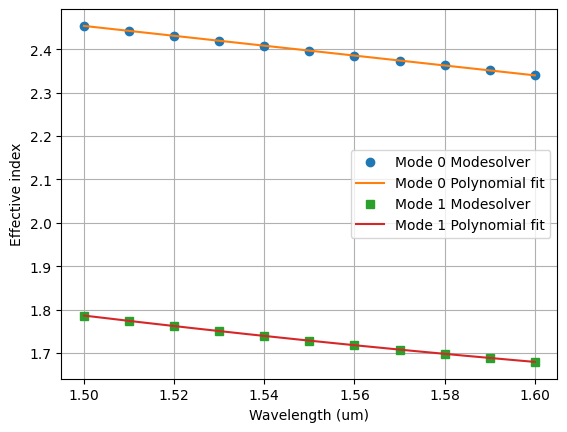

In [39]:
wavelength_fit = np.linspace(wavelength.min(), wavelength.max(), 200)
x_fit = wavelength_fit - 1.55

neff_fit_0 = np.polyval([n3p, n2p, n1p], x_fit)
neff_fit_1 = np.polyval([n3p_1, n2p_1, n1p_1], x_fit)

plt.plot(wavelength, res_neff_si[:,0], 'o', label="Mode 0 Modesolver")
plt.plot(wavelength_fit, neff_fit_0, label="Mode 0 Polynomial fit")

plt.plot(wavelength, res_neff_si[:,1], 's', label="Mode 1 Modesolver")
plt.plot(wavelength_fit, neff_fit_1, label="Mode 1 Polynomial fit")

plt.xlabel("Wavelength (um)")
plt.ylabel("Effective index")
plt.legend()
plt.grid()
plt.show()

## Shallow-Waveguide

In [52]:
wavelength=np.linspace(1.5, 1.6, 11)
shallow_waveguide_si = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=500*nm, 
    slab_thickness=150 * nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=10,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)
res_neff_shallow_si = shallow_waveguide_si.n_eff.real

# Calculate TE and TM fractions for each wavelength

res_te = []
res_tm = []

for wl in wavelength:

    shallow_waveguide_si = gt.modes.Waveguide(
        wavelength=wl,
        core_width=500*nm,
        slab_thickness=150 * nm,
        core_material='si',
        clad_material='sio2',
        core_thickness=220 * nm,
        num_modes=10,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20,
    )

    res_te.append(shallow_waveguide_si.fraction_te)
    res_tm.append(shallow_waveguide_si.fraction_tm)

res_te = np.array(res_te)
res_tm = np.array(res_tm)

print("TE shape:", res_te.shape)
print("TM shape:", res_tm.shape)


# Waveguide at 1550 nm
shallow_waveguide_1550_si = gt.modes.Waveguide(
    wavelength=1550 * nm, 
    core_width=500*nm, 
    slab_thickness=150 * nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=10,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=20, 
)

res_neff_1550 = shallow_waveguide_1550_si.n_eff.real

print(f"neff at 1550nm: {res_neff_1550}")

# Identify TE and TM modes at 1550 nm
posicion_lambda = np.argmin(np.abs(wavelength - 1.55))
print(res_te[posicion_lambda,0])
te_1550 = res_te[posicion_lambda, :]
tm_1550 = res_tm[posicion_lambda, :]

i_TE = np.where(te_1550 > 0.5)[0][0]
i_TM = np.where(tm_1550 > 0.5)[0][0]

print(f"TE: Mode {i_TE}, fraction = {te_1550[i_TE]:.3f}")
print(f"TM: Mode {i_TM}, fraction = {tm_1550[i_TM]:.3f}")

2026-11-09 00:02:02.491 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_d4721563d8d68199.npz.
2026-11-09 00:02:02.503 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_9fe51708653b5b8c.npz.
2026-11-09 00:02:02.512 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_af9016ed35887f9d.npz.
2026-11-09 00:02:02.523 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_5f23c28dd049be0c.npz.
2026-11-09 00:02:02.531 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_cc72bfde4a6bfb7b.npz.
2026-11-09 00:02:02.541 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_85847543951f22a3.npz.
2026-11-09 00:02:02.550 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_afe62a3a188e552b.npz.
2026-11-09 00:02:02.560 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache\Waveguide_541614d795bb94f1.npz.


Wavelength: [1.5  1.51 1.52 1.53 1.54 1.55 1.56 1.57 1.58 1.59 1.6 ]
neff: [2.70094474 2.69370739 2.6865069  2.67934311 2.67221589 2.66512509
 2.6580706  2.6510523  2.64407008 2.63712384 2.6302135 ]


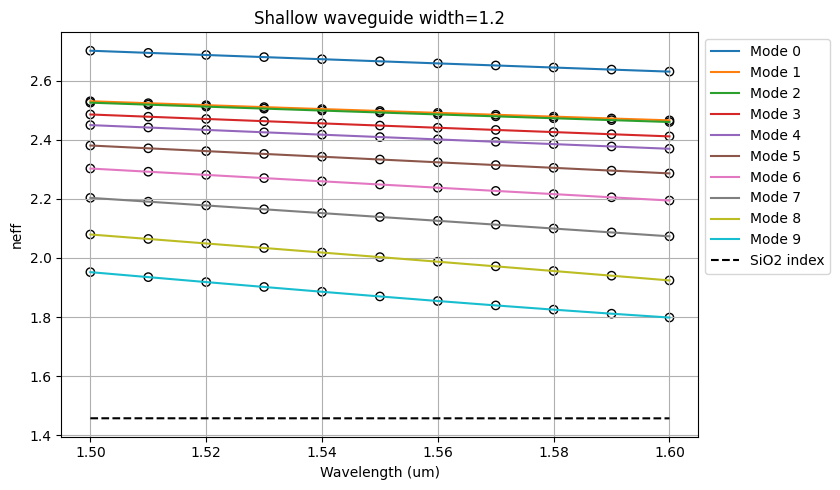

In [50]:
plt.figure(figsize=(10, 5)) #Getting the figure ready to plot
for k in range(res_neff_shallow_si.shape[1]):
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff_shallow_si[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff_shallow_si[:,k].real,label=f'Mode {k}')
plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
print(f"Wavelength: {wavelength}")
print(f"neff: {res_neff_shallow_si[:,0].real}")

In [54]:
#Mode 0 TE0
n3ps,n2ps,n1ps = np.polyfit(wavelength-1.55, res_neff_shallow_si[:,0], 2)

# Mode 9 TM0
n3p_9,n2p_9,n1p_9 = np.polyfit(wavelength-1.55, res_neff_shallow_si[:,9], 2)

print(f"Mode 0: n3 = {n3ps}, n2 = {n2ps}, n1 = {n1ps}")
print(f"Mode 9: n3 = {n3p_9}, n2 = {n2p_9}, n1 = {n1p_9}")

# Group index
ng_0 = n1ps-n2ps*1.55
ng_9 = n1p_9-n2p_9*1.55

print(f"Group index Mode 0: {ng_0}")
print(f"Group index Mode 9: {ng_9}")

# Dispersion
D_0 = -2*1.55e-6/3e8*n3ps
D_9 = -2*1.55e-6/3e8*n3p_9

print(f"Dispersion Mode 0: {D_0}")
print(f"Dispersion Mode 9: {D_9}")

Mode 0: n3 = 0.18161244497079213, n2 = -0.7072979629134898, n1 = 2.6651250639704434
Mode 9: n3 = 2.1758650245445437, n2 = -1.5437242716456847, n1 = 1.8698788021664974
Group index Mode 0: 3.7614369064863524
Group index Mode 9: 4.262651423217309
Dispersion Mode 0: -1.8766619313648517e-15
Dispersion Mode 9: -2.2483938586960284e-14


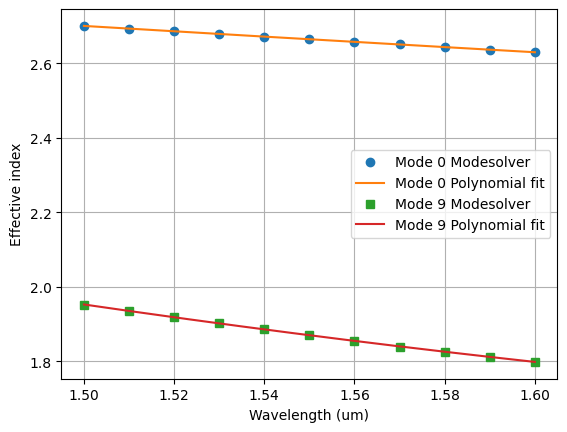

In [55]:
wavelength_fit = np.linspace(wavelength.min(), wavelength.max(), 200)
x_fit = wavelength_fit - 1.55

neff_fit_0 = np.polyval([n3ps, n2ps, n1ps], x_fit)
neff_fit_9 = np.polyval([n3p_9, n2p_9, n1p_9], x_fit)

plt.plot(wavelength, res_neff_shallow_si[:,0], 'o', label="Mode 0 Modesolver")
plt.plot(wavelength_fit, neff_fit_0, label="Mode 0 Polynomial fit")

plt.plot(wavelength, res_neff_shallow_si[:,9], 's', label="Mode 9 Modesolver")
plt.plot(wavelength_fit, neff_fit_2, label="Mode 9 Polynomial fit")

plt.xlabel("Wavelength (um)")
plt.ylabel("Effective index")
plt.legend()
plt.grid()
plt.show()

## Bend Radius

  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
c:\Users\TecnoWPc\Desktop\Portátil-PC\Master PIC\Diseño\Labs Design\pic-upv-lab1\.venv\Lib\site-packages\tidy3d\components\mode\derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
c:\

Text(0, 0.5, 'Mismatch (dB)')

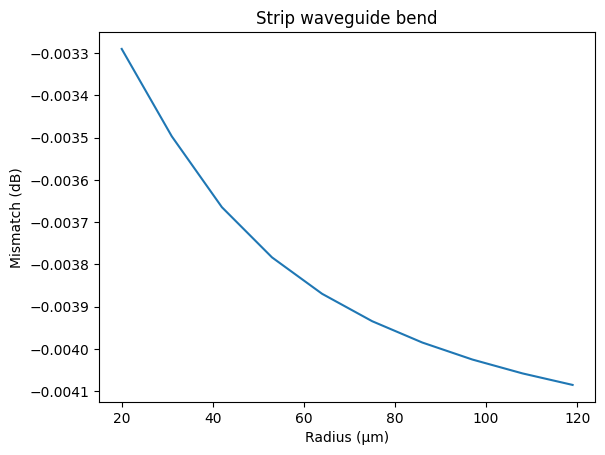

In [58]:
bend_1550_si = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=500*nm,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=1,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.4,
    grid_resolution=30, 
    bend_radius=5, # Bend radius
)

radii = np.arange(20.0, 120,11)

mismatch = gt.modes.sweep_bend_mismatch(bend_1550_si, radii)

plt.plot(radii, 10 * np.log10(mismatch))
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")

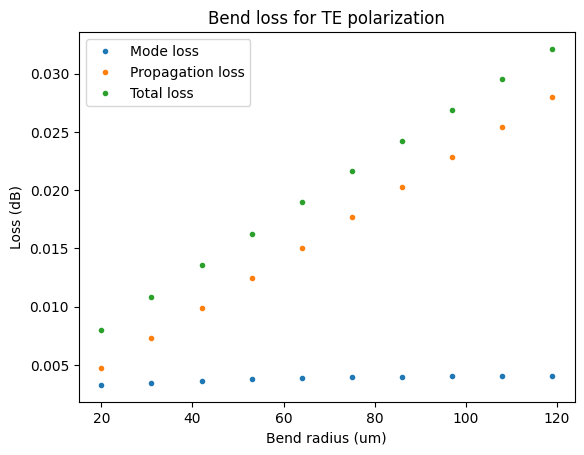

In [59]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss = dB_cm * length * 1e2
propagation_loss

plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch), ".", label="Mode loss")
plt.plot(radii, propagation_loss, ".", label="Propagation loss")
plt.plot(radii, propagation_loss-10 * np.log10(mismatch), ".", label="Total loss")
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()

## Grading

LO.1. 2 Point <br> 
LO.2. 1 Points <br> 
LO.3. 3 Point <br> 
LO.4. 1 Points <br> 
**Total 7 Points** <br>
Extra (Up to) 3 Points
